In [ ]:
!pip -q install google-cloud-bigquery db-dtypes

In [ ]:
from google.colab import auth
auth.authenticate_user()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from google.cloud import bigquery
import pandas as pd

PROJECT_ID = "project-ae5e7ed7-5218-49e9-91d"
DATASET = "multimodal_labs_vitals"
client = bigquery.Client(project=PROJECT_ID)

print("Connected to:", PROJECT_ID)

Connected to: project-ae5e7ed7-5218-49e9-91d


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import gdown

##Table generation query for replication
 joins modality availability info (+age, sex, died 1yr) with race, insurance, and language from MIMIC-IV hospital admissions

In [ ]:
## query for loaded table, for replicating table
demo_comp_table_gen = f"""
CREATE OR REPLACE TABLE `{PROJECT_ID}.{DATASET}.demo_comp`

AS

SELECT

  c.subject_id,
  c.stay_id,
  c.hadm_id,
  c.level_id,
  c.age,
  c.sex,
  a.race,
  a.insurance,
  a.language,
  c.has_all5,
  c.has_vitals,
  c.n_vitals_base,
  c.has_labs,
  c.n_labs_base,
  c.has_notes,
  c.has_ecg,
  c.has_cxr,
  c.died_1y

FROM `ace-apex-508114-n9.phase0.analysis_dataset` AS c

LEFT JOIN `physionet-data.mimiciv_3_1_hosp.admissions` AS a
ON c.subject_id = a.subject_id AND c.hadm_id = a.hadm_id
;
"""

# Loading Initial Table

In [ ]:
demo_query = f"""SELECT *
FROM `{PROJECT_ID}.{DATASET}.demo_comp`
ORDER BY subject_id, stay_id, level_id"""

demo_df = client.query(demo_query).to_dataframe()
demo_df.rename(columns={'sex':'gender'}, inplace=True)

print("Info shape:", demo_df.shape)
print("Demographics/Modality Info: ", demo_df.columns)
display(demo_df.head())

Info shape: (30105, 18)
Demographics/Modality Info:  Index(['subject_id', 'stay_id', 'hadm_id', 'level_id', 'age', 'gender', 'race',
       'insurance', 'language', 'has_all5', 'has_vitals', 'n_vitals_base',
       'has_labs', 'n_labs_base', 'has_notes', 'has_ecg', 'has_cxr',
       'died_1y'],
      dtype='object')


,subject_id,stay_id,hadm_id,level_id,age,gender,race,insurance,language,has_all5,has_vitals,n_vitals_base,has_labs,n_labs_base,has_notes,has_ecg,has_cxr,died_1y
0,10002013,39060235,23581541,L3,57.0,F,OTHER,Medicare,English,False,True,33,True,19,True,True,False,False
1,10002114,34672098,27793700,L2,56.0,M,UNKNOWN,Medicaid,English,False,True,65,True,24,False,False,False,True
2,10002114,34672098,27793700,L3,56.0,M,UNKNOWN,Medicaid,English,False,True,65,True,24,False,False,False,True
3,10002155,33685454,23822395,L1,81.0,F,WHITE,Medicare,English,False,True,31,True,12,True,True,False,False
4,10002155,33685454,23822395,L2,81.0,F,WHITE,Medicare,English,False,True,31,True,12,True,True,False,False


# Creating Summary Statistic DataFrame

## Creating Race Groupings

Defining race groupings

In [ ]:
race_groupings = {
    'WHITE':                                     'WHITE',
    'WHITE - RUSSIAN':                           'WHITE',
    'WHITE - BRAZILIAN':                         'WHITE',
    'WHITE - OTHER EUROPEAN':                    'WHITE',
    'WHITE - EASTERN EUROPEAN':                  'WHITE',

    'UNKNOWN':                                   'UNKNOWN',
    'UNABLE TO OBTAIN':                          'UNKNOWN',
    'PATIENT DECLINED TO ANSWER':                'UNKNOWN',

    'ASIAN - KOREAN':                            'ASIAN',
    'ASIAN':                                     'ASIAN',
    'ASIAN - SOUTH EAST ASIAN':                  'ASIAN',
    'ASIAN - CHINESE':                           'ASIAN',
    'ASIAN - ASIAN INDIAN':                      'ASIAN',

    'HISPANIC OR LATINO':                        'HISPANIC/LATINO',
    'HISPANIC/LATINO - PUERTO RICAN':            'HISPANIC/LATINO',
    'HISPANIC/LATINO - DOMINICAN':               'HISPANIC/LATINO',
    'HISPANIC/LATINO - COLUMBIAN':               'HISPANIC/LATINO',
    'HISPANIC/LATINO - HONDURAN':                'HISPANIC/LATINO',
    'HISPANIC/LATINO - MEXICAN':                 'HISPANIC/LATINO',
    'HISPANIC/LATINO - SALVADORAN':              'HISPANIC/LATINO',
    'HISPANIC/LATINO - GUATEMALAN':              'HISPANIC/LATINO',
    'HISPANIC/LATINO - CUBAN':                   'HISPANIC/LATINO',
    'HISPANIC/LATINO - CENTRAL AMERICAN':        'HISPANIC/LATINO',

    'BLACK/AFRICAN AMERICAN':                    'BLACK',
    'BLACK/CARIBBEAN ISLAND':                    'BLACK',
    'BLACK/CAPE VERDEAN':                        'BLACK',
    'BLACK/AFRICAN':                             'BLACK',

    'OTHER':                                     'OTHER',
    'PORTUGUESE':                                'OTHER',
    'AMERICAN INDIAN/ALASKA NATIVE':             'OTHER',
    'MULTIPLE RACE/ETHNICITY':                   'OTHER',
    'NATIVE HAWAIIAN OR OTHER PACIFIC ISLANDER': 'OTHER',
    'SOUTH AMERICAN':                            'OTHER'
}

In [ ]:
# mapping races to their respective race groups
demo_df["race_group"] = demo_df["race"].map(race_groupings)

In [ ]:
demo_df.head()

,subject_id,stay_id,hadm_id,level_id,age,gender,race,insurance,language,has_all5,has_vitals,n_vitals_base,has_labs,n_labs_base,has_notes,has_ecg,has_cxr,died_1y,race_group
0,10002013,39060235,23581541,L3,57.0,F,OTHER,Medicare,English,False,True,33,True,19,True,True,False,False,OTHER
1,10002114,34672098,27793700,L2,56.0,M,UNKNOWN,Medicaid,English,False,True,65,True,24,False,False,False,True,UNKNOWN
2,10002114,34672098,27793700,L3,56.0,M,UNKNOWN,Medicaid,English,False,True,65,True,24,False,False,False,True,UNKNOWN
3,10002155,33685454,23822395,L1,81.0,F,WHITE,Medicare,English,False,True,31,True,12,True,True,False,False,WHITE
4,10002155,33685454,23822395,L2,81.0,F,WHITE,Medicare,English,False,True,31,True,12,True,True,False,False,WHITE


In [ ]:
race_groupings_list = ["WHITE", "BLACK", "HISPANIC/LATINO", "ASIAN", "OTHER", "UNKNOWN", "ALL"]

## Putting It All Together

Goal: create a summary table containing sumary stats for each race group (White, Black, Asian, Hispanic/Latino, Unknown, Other)

In [ ]:
#creating one dataframe for each level
l3_demo_df = demo_df[demo_df['level_id']=='L3'].copy()
l2_demo_df = demo_df[demo_df['level_id']=='L2'].copy()
l1_demo_df = demo_df[demo_df['level_id']=='L1'].copy()

print("Participants in L3: ", l3_demo_df.shape[0])
print("Participants in L2: ", l2_demo_df.shape[0])
print("Participants in L1: ", l1_demo_df.shape[0])

Participants in L3:  18391
Participants in L2:  7218
Participants in L1:  4496


Summary statistic calculator

In [ ]:
def summarize_race_group(df, race_group, return_raw_numbers=False):
    """
    Calculate summary statistics for a given race group from data in df

    Input:
    - df (dataframe): dataframe from which to summarize race data
    - race_group (str): race group to summarize

    Returns:
    - (dataframe): dataframe containing summary statistics for race group
    """
    if race_group == 'ALL':
      just_race = df
    else:
      just_race = df[df['race_group'] == race_group]

    # fraction of total dataset
    global_n = len(df)
    n = len(just_race)
    numerical_proportion = n / global_n

    #modalities
    has_vitals_proportion = just_race['has_vitals'].value_counts()[True] / n
    n_vitals_mean = just_race['n_vitals_base'].mean()
    n_vitals_median = just_race['n_vitals_base'].median()
    n_vitals_std = just_race['n_vitals_base'].std()

    has_labs_proportion = just_race['has_labs'].value_counts()[True] / n
    n_labs_mean = just_race['n_labs_base'].mean()
    n_labs_median = just_race['n_labs_base'].median()
    n_labs_std = just_race['n_labs_base'].std()
    has_ecg_proportion = just_race['has_ecg'].value_counts()[True] / n
    has_notes_proportion = just_race['has_notes'].value_counts()[True] / n
    has_cxr_proportion = just_race['has_cxr'].value_counts()[True] / n
    has_all5_proportion = just_race['has_all5'].value_counts()[True] / n

    died_1y_proportion = just_race['died_1y'].value_counts()[True] / n

    # gender
    male_proportion =   just_race['gender'].value_counts()['M'] / n
    female_proportion = just_race['gender'].value_counts()['F'] / n

    # age
    age_mean =   just_race['age'].mean()
    age_median = just_race['age'].median()
    age_std =    just_race['age'].std()

    #language
    language_proportion = just_race['language'].value_counts()['English']/n

    #insurance
    medicaid_proportion = just_race['insurance'].value_counts()['Medicaid']/n
    medicare_proportion = just_race['insurance'].value_counts()['Medicare']/n
    private_proportion = just_race['insurance'].value_counts()['Private']/n
    other_proportion = just_race['insurance'].value_counts().get('Other', 0)/n
    none_proportion = just_race['insurance'].value_counts(dropna=False).get(None, 0)/n


    # putting it all together
    if return_raw_numbers:
      summary_list = [float(n),
                      has_vitals_proportion *n,
                      n_vitals_mean,
                      n_vitals_median,
                      n_vitals_std,
                      has_labs_proportion *n,
                      n_labs_mean,
                      n_labs_median,
                      n_labs_std,
                      has_ecg_proportion*n,
                      has_notes_proportion*n,
                      has_cxr_proportion*n,
                      has_all5_proportion*n,
                      died_1y_proportion*n,
                      male_proportion * n,
                      female_proportion * n,
                      age_mean,
                      age_median,
                      age_std,
                      language_proportion*n,
                      medicaid_proportion*n,
                      medicare_proportion*n,
                      private_proportion*n,
                      other_proportion*n,
                      none_proportion*n
                      ]
    else:
      summary_list = [numerical_proportion,
                      has_vitals_proportion,
                      n_vitals_mean,
                      n_vitals_median,
                      n_vitals_std,
                      has_labs_proportion,
                      n_labs_mean,
                      n_labs_median,
                      n_labs_std,
                      has_ecg_proportion,
                      has_notes_proportion,
                      has_cxr_proportion,
                      has_all5_proportion,
                      died_1y_proportion,
                      male_proportion,
                      female_proportion,
                      age_mean,
                      age_median,
                      age_std,
                      language_proportion,
                      medicare_proportion,
                      medicaid_proportion,
                      private_proportion,
                      other_proportion,
                      none_proportion
                     ]
    # rounding
    for i in range(len(summary_list)):
      summary_list[i] = np.round(summary_list[i],3)

    return summary_list

In [ ]:
# example
summarize_race_group(l3_demo_df,'WHITE',return_raw_numbers=True)

[np.float64(12794.0),
 np.float64(12784.0),
 np.float64(39.067),
 np.float64(35.0),
 np.float64(14.259),
 np.float64(12785.0),
 np.float64(22.013),
 np.float64(21.0),
 np.float64(9.297),
 np.float64(8795.0),
 np.float64(9726.0),
 np.float64(1723.0),
 np.float64(1644.0),
 np.float64(8345.0),
 np.float64(4449.0),
 np.float64(69.443),
 np.float64(70.0),
 np.float64(13.014),
 np.float64(12331.0),
 np.float64(871.0),
 np.float64(8077.0),
 np.float64(3570.0),
 np.float64(203.0),
 np.float64(73.0)]

In [ ]:
summarize_race_group(l3_demo_df,'WHITE',return_raw_numbers=False)

[np.float64(0.696),
 np.float64(0.999),
 np.float64(39.067),
 np.float64(35.0),
 np.float64(14.259),
 np.float64(0.999),
 np.float64(22.013),
 np.float64(21.0),
 np.float64(9.297),
 np.float64(0.687),
 np.float64(0.76),
 np.float64(0.135),
 np.float64(0.128),
 np.float64(0.652),
 np.float64(0.348),
 np.float64(69.443),
 np.float64(70.0),
 np.float64(13.014),
 np.float64(0.964),
 np.float64(0.631),
 np.float64(0.068),
 np.float64(0.279),
 np.float64(0.016),
 np.float64(0.006)]

Creating summary dataframe using summary statisic caluclator function

In [ ]:
def create_summary_df(df, race_groups, race_in_cols=False):
  data = []
  for race_group in race_groups:
    data.append(summarize_race_group(df,race_group))

  summary_df = pd.DataFrame(data=data,
                            index=race_groups,
                            columns=["Dataset Frequency (proportion)",
                                     "Has Vitals (proportion)",
                                     "Vitals (mean)",
                                     "Vitals (median)",
                                     "Vitals (std)",
                                     "Has Labs (proportion)",
                                     "Labs (mean)",
                                     "Labs (median)",
                                     "Labs (std)",
                                     "Has ECG (proportion)",
                                     "Has Notes (proportion)",
                                     "Has Chest X-Ray (proportion)",
                                     "Has All 5 (proportion)",
                                     "Died within 1 year (proportion)",
                                     "Male (proportion)",
                                     "Female (proportion)",
                                     "Age (mean)",
                                     "Age (median)",
                                     "Age (std)",
                                     "English (proportion)",
                                     "Insurance:Medicare (proportion)",
                                     "Insurance:Medicaid (proportion)",
                                     "Insurance:Private (proportion)",
                                     "Insurance:Other (proportion)",
                                     "Insurance:None (proportion)"])
  if race_in_cols:
    summary_df = summary_df.transpose()
  return summary_df


In [ ]:
print('Level 3')
l3_summary_df = create_summary_df(l3_demo_df,race_groupings_list)
l3_summary_df

Level 3


,Dataset Frequency (proportion),Has Vitals (proportion),Vitals (mean),Vitals (median),Vitals (std),Has Labs (proportion),Labs (mean),Labs (median),Labs (std),Has ECG (proportion),...,Female (proportion),Age (mean),Age (median),Age (std),English (proportion),Insurance:Medicare (proportion),Insurance:Medicaid (proportion),Insurance:Private (proportion),Insurance:Other (proportion),Insurance:None (proportion)
WHITE,0.696,0.999,39.067,35.0,14.259,0.999,22.013,21.0,9.297,0.687,...,0.348,69.443,70.0,13.014,0.964,0.631,0.068,0.279,0.016,0.006
BLACK,0.067,1.000,41.421,37.0,16.155,0.998,21.508,20.0,9.606,0.624,...,0.500,64.331,65.0,15.058,0.888,0.513,0.200,0.247,0.031,0.008
HISPANIC/LATINO,0.030,0.998,39.909,36.0,15.012,0.998,22.495,22.0,8.868,0.641,...,0.365,61.791,62.0,14.378,0.330,0.416,0.338,0.176,0.056,0.015
ASIAN,0.024,1.000,38.716,35.0,13.773,1.000,22.626,21.0,10.203,0.624,...,0.351,65.721,66.0,14.178,0.467,0.386,0.252,0.321,0.023,0.018
OTHER,0.041,1.000,38.959,35.0,12.996,1.000,21.814,21.0,9.588,0.642,...,0.342,66.345,68.0,14.901,0.782,0.516,0.168,0.273,0.029,0.013
UNKNOWN,0.143,1.000,39.130,35.0,14.505,0.999,22.740,23.0,10.113,0.601,...,0.315,67.441,69.0,13.268,0.891,0.563,0.109,0.287,0.022,0.018
ALL,1.000,0.999,39.245,35.0,14.402,0.999,22.104,21.0,9.465,0.666,...,0.353,68.372,69.0,13.482,0.910,0.597,0.099,0.276,0.020,0.009


In [ ]:
print('Level 2')
l2_summary_df = create_summary_df(l2_demo_df,race_groupings_list)
l2_summary_df

Level 2


,Dataset Frequency (proportion),Has Vitals (proportion),Vitals (mean),Vitals (median),Vitals (std),Has Labs (proportion),Labs (mean),Labs (median),Labs (std),Has ECG (proportion),...,Female (proportion),Age (mean),Age (median),Age (std),English (proportion),Insurance:Medicare (proportion),Insurance:Medicaid (proportion),Insurance:Private (proportion),Insurance:Other (proportion),Insurance:None (proportion)
WHITE,0.679,0.999,42.688,39.0,16.789,1.000,16.872,15.0,8.141,0.699,...,0.427,71.529,74.0,14.691,0.951,0.704,0.065,0.209,0.015,0.006
BLACK,0.092,1.000,43.085,41.0,16.205,0.997,17.928,16.0,8.068,0.643,...,0.513,64.475,66.0,16.332,0.904,0.553,0.195,0.219,0.025,0.007
HISPANIC/LATINO,0.029,0.995,44.560,41.0,18.822,0.995,18.167,17.0,8.409,0.627,...,0.426,61.694,62.0,15.547,0.364,0.478,0.330,0.124,0.048,0.019
ASIAN,0.024,1.000,43.023,39.5,16.904,1.000,18.216,17.0,8.491,0.614,...,0.432,69.528,71.0,15.705,0.398,0.455,0.210,0.267,0.040,0.028
OTHER,0.041,1.000,43.949,40.0,18.150,1.000,17.034,15.0,8.950,0.653,...,0.435,67.337,69.0,16.724,0.762,0.571,0.163,0.204,0.037,0.024
UNKNOWN,0.135,0.999,43.618,41.0,16.135,0.999,16.820,15.0,9.027,0.642,...,0.372,68.485,70.0,14.732,0.909,0.602,0.120,0.214,0.032,0.031
ALL,1.000,0.999,42.963,39.0,16.773,0.999,17.039,15.0,8.317,0.680,...,0.428,69.963,72.0,15.220,0.903,0.659,0.100,0.210,0.021,0.011


In [ ]:
print('Level 1')
l1_summary_df = create_summary_df(l1_demo_df,race_groupings_list)
l1_summary_df

Level 1


,Dataset Frequency (proportion),Has Vitals (proportion),Vitals (mean),Vitals (median),Vitals (std),Has Labs (proportion),Labs (mean),Labs (median),Labs (std),Has ECG (proportion),...,Female (proportion),Age (mean),Age (median),Age (std),English (proportion),Insurance:Medicare (proportion),Insurance:Medicaid (proportion),Insurance:Private (proportion),Insurance:Other (proportion),Insurance:None (proportion)
WHITE,0.692,0.999,43.299,40.0,16.925,0.999,18.069,17.0,8.335,0.693,...,0.419,74.152,76.0,13.138,0.944,0.772,0.056,0.157,0.012,0.003
BLACK,0.097,1.000,44.460,41.0,18.026,0.995,19.221,18.0,8.730,0.641,...,0.497,67.393,69.0,14.712,0.892,0.614,0.186,0.172,0.021,0.007
HISPANIC/LATINO,0.026,1.000,43.254,41.5,12.130,1.000,19.881,19.0,8.724,0.619,...,0.432,61.678,62.0,14.671,0.339,0.500,0.347,0.102,0.025,0.025
ASIAN,0.021,1.000,44.396,41.0,19.202,1.000,20.573,18.5,9.378,0.604,...,0.458,72.667,75.0,13.464,0.344,0.531,0.229,0.219,0.010,0.010
OTHER,0.040,1.000,43.055,39.0,19.473,1.000,18.077,16.0,9.204,0.624,...,0.431,69.597,72.0,15.034,0.768,0.630,0.155,0.171,0.022,0.022
UNKNOWN,0.124,1.000,44.162,42.0,15.905,0.998,17.680,16.0,9.369,0.614,...,0.370,70.706,72.0,13.502,0.914,0.661,0.117,0.172,0.027,0.023
ALL,1.000,0.999,43.531,40.0,16.963,0.999,18.234,17.0,8.592,0.672,...,0.422,72.528,74.0,13.766,0.899,0.725,0.091,0.161,0.015,0.007


Rotated version

In [ ]:
l1_summary_df_rotated = l1_summary_df.transpose()
l1_summary_df_rotated

,WHITE,BLACK,HISPANIC/LATINO,ASIAN,OTHER,UNKNOWN,ALL
Dataset Frequency (proportion),0.692,0.097,0.026,0.021,0.040,0.124,1.000
Has Vitals (proportion),0.999,1.000,1.000,1.000,1.000,1.000,0.999
Vitals (mean),43.299,44.460,43.254,44.396,43.055,44.162,43.531
Vitals (median),40.000,41.000,41.500,41.000,39.000,42.000,40.000
Vitals (std),16.925,18.026,12.130,19.202,19.473,15.905,16.963
Has Labs (proportion),0.999,0.995,1.000,1.000,1.000,0.998,0.999
Labs (mean),18.069,19.221,19.881,20.573,18.077,17.680,18.234
Labs (median),17.000,18.000,19.000,18.500,16.000,16.000,17.000
Labs (std),8.335,8.730,8.724,9.378,9.204,9.369,8.592
Has ECG (proportion),0.693,0.641,0.619,0.604,0.624,0.614,0.672


## Enforcing Modality Criteria

In [ ]:
#creating one dataframe for each level for participants with all 5 modalities
l3all_demo_df = l3_demo_df[l3_demo_df['has_all5']== True].copy()
l2all_demo_df = l2_demo_df[l2_demo_df['has_all5']== True].copy()
l1all_demo_df = l1_demo_df[l1_demo_df['has_all5']== True].copy()

print("Participants w/all modalities in L3: ", l3all_demo_df.shape[0])
print("Participants w/all modalities in L2: ", l2all_demo_df.shape[0])
print("Participants w/all modalities in L1: ", l1all_demo_df.shape[0])

Participants w/all modalities in L3:  2323
Participants w/all modalities in L2:  1489
Participants w/all modalities in L1:  997


In [ ]:
l1all_summary_df  = create_summary_df(l1all_demo_df,race_groupings_list)
l2all_summary_df  = create_summary_df(l2all_demo_df,race_groupings_list)
l3all_summary_df  = create_summary_df(l3all_demo_df,race_groupings_list)

In [ ]:
l1all_summary_df.transpose()

,WHITE,BLACK,HISPANIC/LATINO,ASIAN,OTHER,UNKNOWN,ALL
Dataset Frequency (proportion),0.706,0.134,0.032,0.025,0.049,0.053,1.000
Has Vitals (proportion),1.000,1.000,1.000,1.000,1.000,1.000,1.000
Vitals (mean),40.908,40.910,42.438,36.120,40.204,43.604,40.946
Vitals (median),35.000,34.000,40.000,31.000,39.000,40.000,36.000
Vitals (std),17.430,15.931,12.879,10.783,11.853,17.009,16.710
Has Labs (proportion),1.000,1.000,1.000,1.000,1.000,1.000,1.000
Labs (mean),18.213,18.216,17.750,18.480,18.184,20.604,18.331
Labs (median),17.000,17.000,17.000,16.000,17.000,18.000,17.000
Labs (std),7.715,7.243,6.016,7.875,8.108,12.688,7.969
Has ECG (proportion),1.000,1.000,1.000,1.000,1.000,1.000,1.000


In [ ]:
summary_df_list = [l1_summary_df, l2_summary_df, l3_summary_df, l1all_summary_df, l2all_summary_df, l3all_summary_df]
df_list = [l1_demo_df, l2_demo_df, l3_demo_df, l1all_demo_df, l2all_demo_df, l3all_demo_df]

In [ ]:
def race_level_summary(race_group, df_list):
  summary_list = []
  for df in df_list:
    summary_list.append(df.loc[race_group])
  summary_df = pd.DataFrame(summary_list, index=['L1','L2','L3','L1+','L2+','L3+'])
  return summary_df

In [ ]:
white_summary_df = race_level_summary('WHITE', summary_df_list)

In [ ]:
white_summary_df.transpose()

,L1,L2,L3,L1+,L2+,L3+
Dataset Frequency (proportion),0.692,0.679,0.696,0.706,0.698,0.708
Has Vitals (proportion),0.999,0.999,0.999,1.000,1.000,1.000
Vitals (mean),43.299,42.688,39.067,40.908,40.597,40.221
Vitals (median),40.000,39.000,35.000,35.000,35.000,35.000
Vitals (std),16.925,16.789,14.259,17.430,16.746,15.222
Has Labs (proportion),0.999,1.000,0.999,1.000,1.000,1.000
Labs (mean),18.069,16.872,22.013,18.213,17.477,20.855
Labs (median),17.000,15.000,21.000,17.000,16.000,19.000
Labs (std),8.335,8.141,9.297,7.715,7.443,9.508
Has ECG (proportion),0.693,0.699,0.687,1.000,1.000,1.000


#visualisations

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

##summary renames

In [ ]:
columns_rename = {"Dataset Frequency (proportion)": 'freq',
                  "Has Vitals (proportion)": "vitals_prop",
                  "Vitals (mean)": "vitals_mean",
                  "Vitals (median)": "vitals_median",
                  "Vitals (std)": "vitals_std",
                  "Has Labs (proportion)": "labs_prop",
                  "Labs (mean)": "labs_mean",
                  "Labs (median)": "labs_median",
                  "Labs (std)": "labs_std",
                  "Has ECG (proportion)": "ecg_prop",
                  "Has Notes (proportion)": "notes_prop",
                  "Has Chest X-Ray (proportion)": "cxr_prop",
                  "Has All 5 (proportion)": "all5_prop",
                  "Died within 1 year (proportion)": "died_1y_prop",
                  "Male (proportion)": "male_prop",
                  "Female (proportion)": "female_prop",
                  "Age (mean)": "age_mean",
                  "Age (median)": "age_median",
                  "Age (std)": "age_std",
                  "English (proportion)": "english_prop",
                  "Insurance:Medicare (proportion)": "medicare_prop",
                  "Insurance:Medicaid (proportion)": "medicaid_prop",
                  "Insurance:Private (proportion)": "private_prop",
                  "Insurance:Other (proportion)": "other_prop",
                  "Insurance:None (proportion)": "none_prop"}

index_rename = {"WHITE":"white", "BLACK": "black", "HISPANIC/LATINO": "hispanic_latino", "ASIAN": "asian","OTHER": "other","ALL": "all", "UNKNOWN": "unknown"}

l1summ = l1_summary_df.rename(columns=columns_rename, index=index_rename)
l2summ = l2_summary_df.rename(columns=columns_rename, index=index_rename)
l3summ = l3_summary_df.rename(columns=columns_rename, index=index_rename)

l1all5summ = l1all_summary_df.rename(columns=columns_rename, index=index_rename)
l2all5summ = l2all_summary_df.rename(columns=columns_rename, index=index_rename)
l3all5summ = l3all_summary_df.rename(columns=columns_rename, index=index_rename)

In [ ]:
summ_list = [l1summ, l2summ, l3summ, l1all5summ, l2all5summ, l3all5summ]
titles = ['L1', 'L2', 'L3', 'L1 All 5', 'L2 All 5', 'L3 All 5']

##age histograms

###cohort

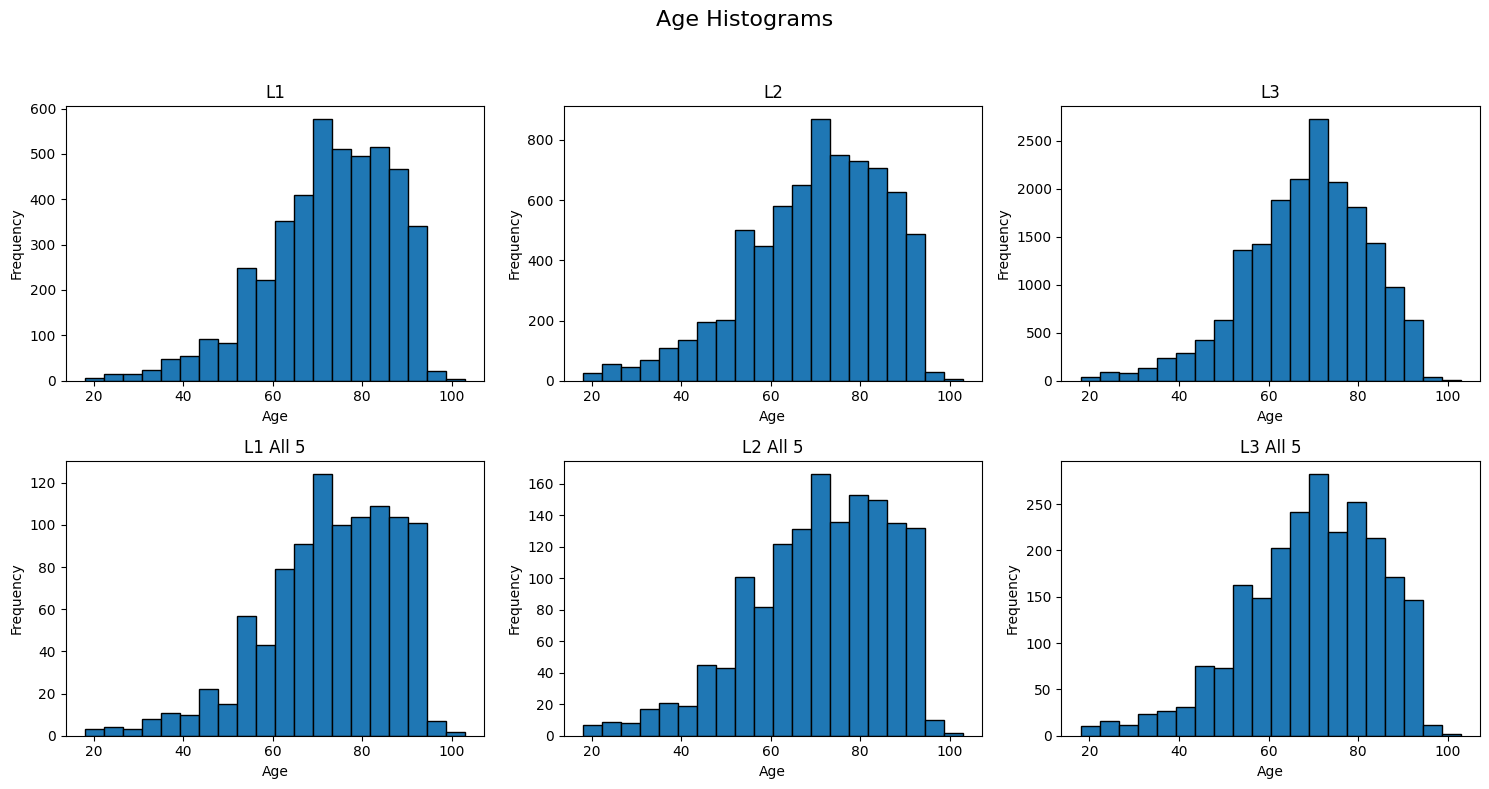

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

age_bins = np.linspace(min(df['age'].min() for df in df_list), max(df['age'].max() for df in df_list), 21)

for i, (df, title) in enumerate(zip(df_list, titles)):
    axes[i].hist(df['age'].dropna(), bins=age_bins, edgecolor='black')
    axes[i].set_title(title)
    axes[i].set_xlabel('Age')
    axes[i].set_ylabel('Frequency')

fig.suptitle('Age Histograms', fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

###race in primary (l1 all 5)

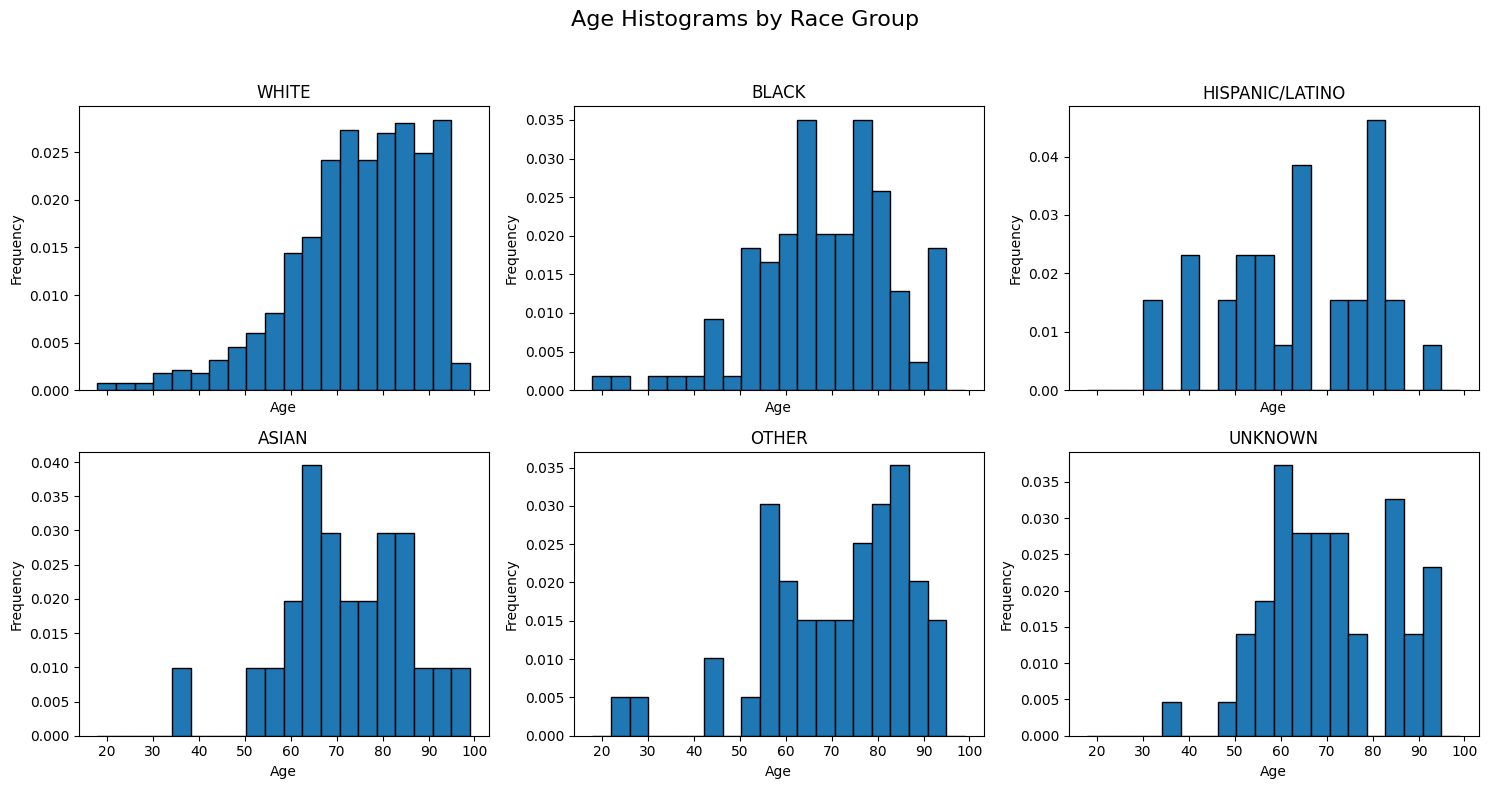

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True)
axes = axes.flatten()

# Use the same bins across all race groups
vitals1_bins = np.linspace(
    l1all_demo_df['age'].min(),
    l1all_demo_df['age'].max(),
    21
)

for i, race_group in enumerate(race_groupings_list[:-1]):
    race_df = l1all_demo_df[
        l1all_demo_df['race_group'] == race_group
    ]

    axes[i].hist(
        race_df['age'].dropna(),
        bins=vitals1_bins,
        edgecolor='black',
        density=True
    )
    axes[i].set_title(str(race_group))
    axes[i].set_xlabel('Age')
    axes[i].set_ylabel('Frequency')

# Hide unused subplots if there are fewer than 6 race groups
for j in range(len(race_groupings_list), len(axes)):
    axes[j].set_visible(False)

fig.suptitle('Age Histograms by Race Group for primary cohort (n=997)', fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

###race pie by cohort

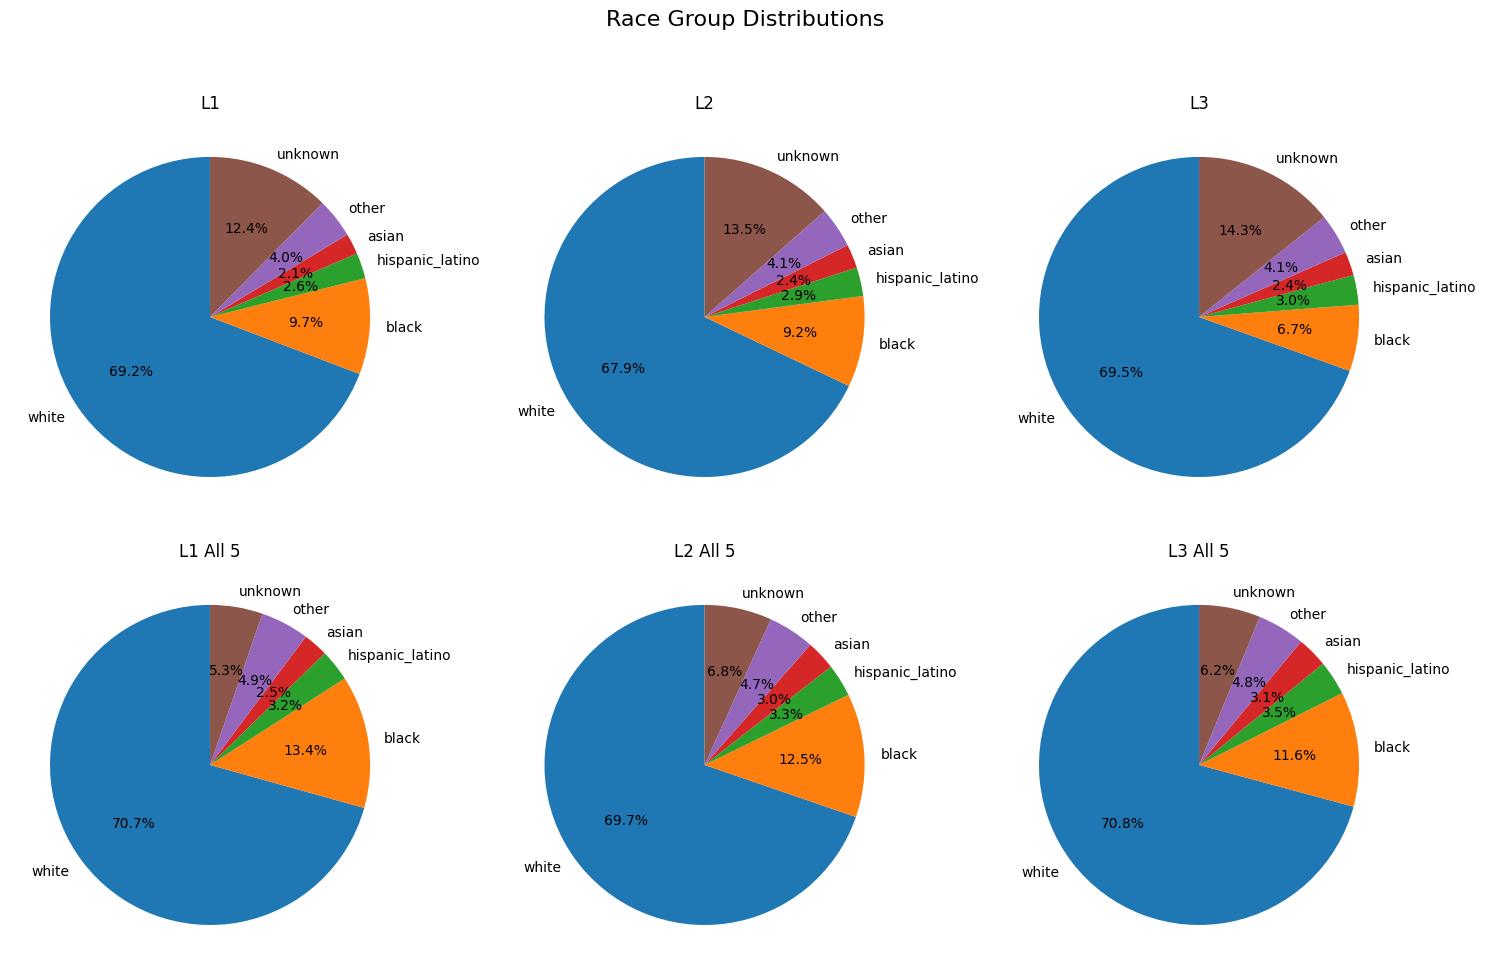

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for ax, df, title in zip(axes, summ_list, titles):
    df_plot = df.loc[df.index != 'all']
    proportions = df_plot['freq'].fillna(0)

    ax.pie(
        proportions,
        labels=proportions.index.astype(str),
        autopct='%1.1f%%',
        startangle=90
    )
    ax.set_title(title)

fig.suptitle('Race Group Distributions', fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

##modality percentage by race

plus lab and vital histograms

In [ ]:
def do_they_have_dist(column, x_label,fulltitle):
  fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)

  for ax, df, title in zip(axes, summ_list[:3], titles[:3]):
      ax.set_ylim(0, 100)
      values = df[column]
      percentages = values * 100

      bars = ax.bar(df.index.astype(str), percentages, edgecolor='black')

      # Show percentages above each bar
      ax.bar_label(bars, fmt='%.1f%%', padding=3)

      ax.set_title(title)
      ax.set_ylabel('Percentage (%)')
      ax.set_xlabel(x_label)
      ax.tick_params(axis='x', rotation=45)

  fig.suptitle(fulltitle, fontsize=16)
  plt.tight_layout(rect=[0, 0, 1, 0.93])
  plt.show()



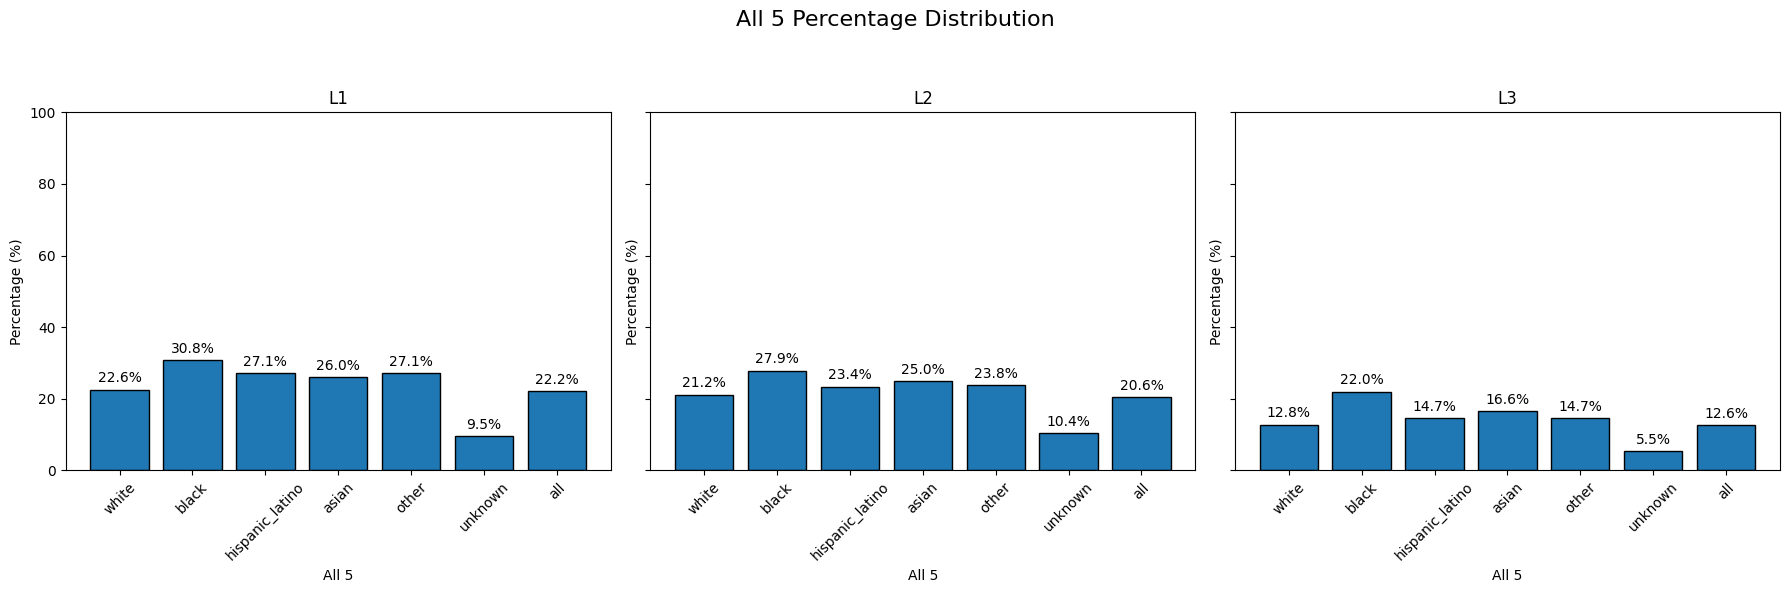

In [ ]:
column = 'all5_prop'
x_label = 'All 5'
sup_title = 'All 5 Percentage Distribution'
do_they_have_dist(column, x_label,sup_title)

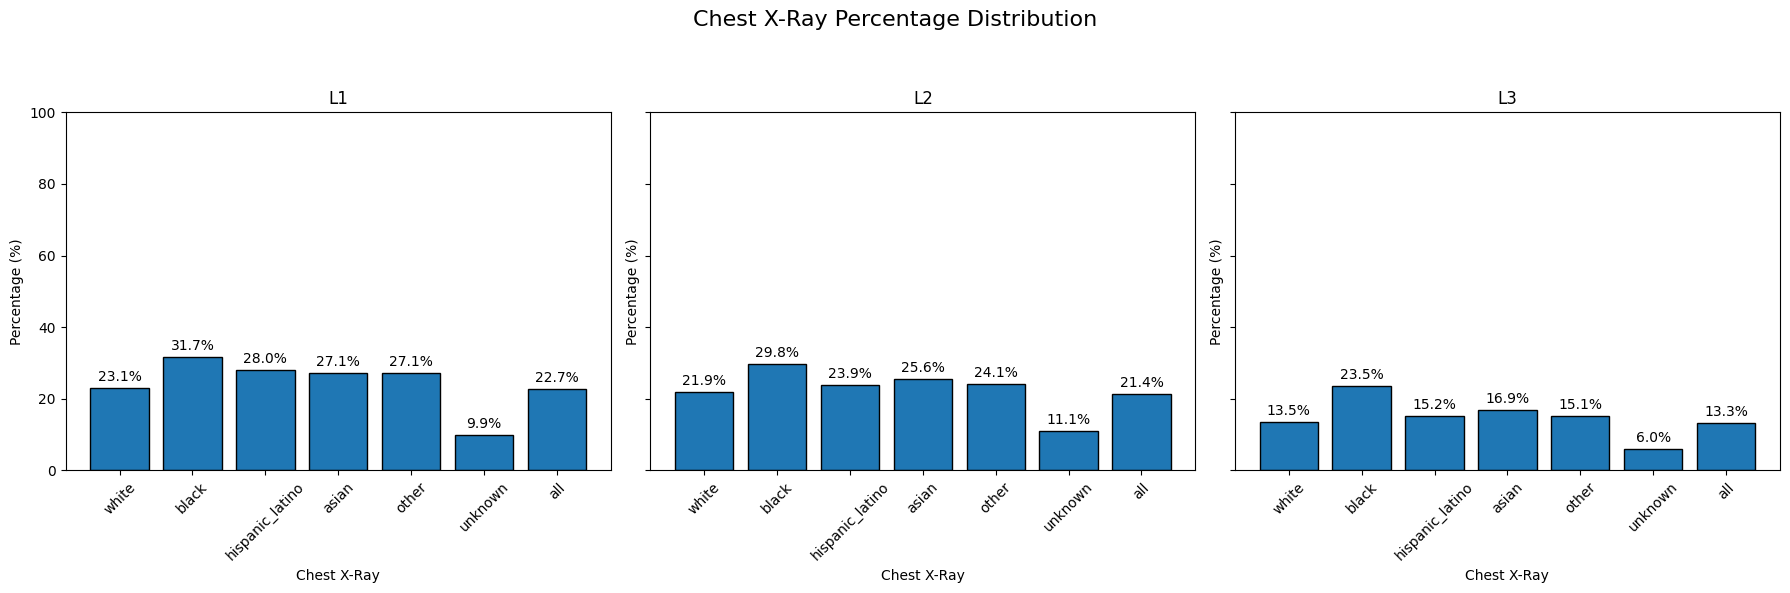

In [ ]:
do_they_have_dist('cxr_prop', 'Chest X-Ray', 'Chest X-Ray Percentage Distribution')

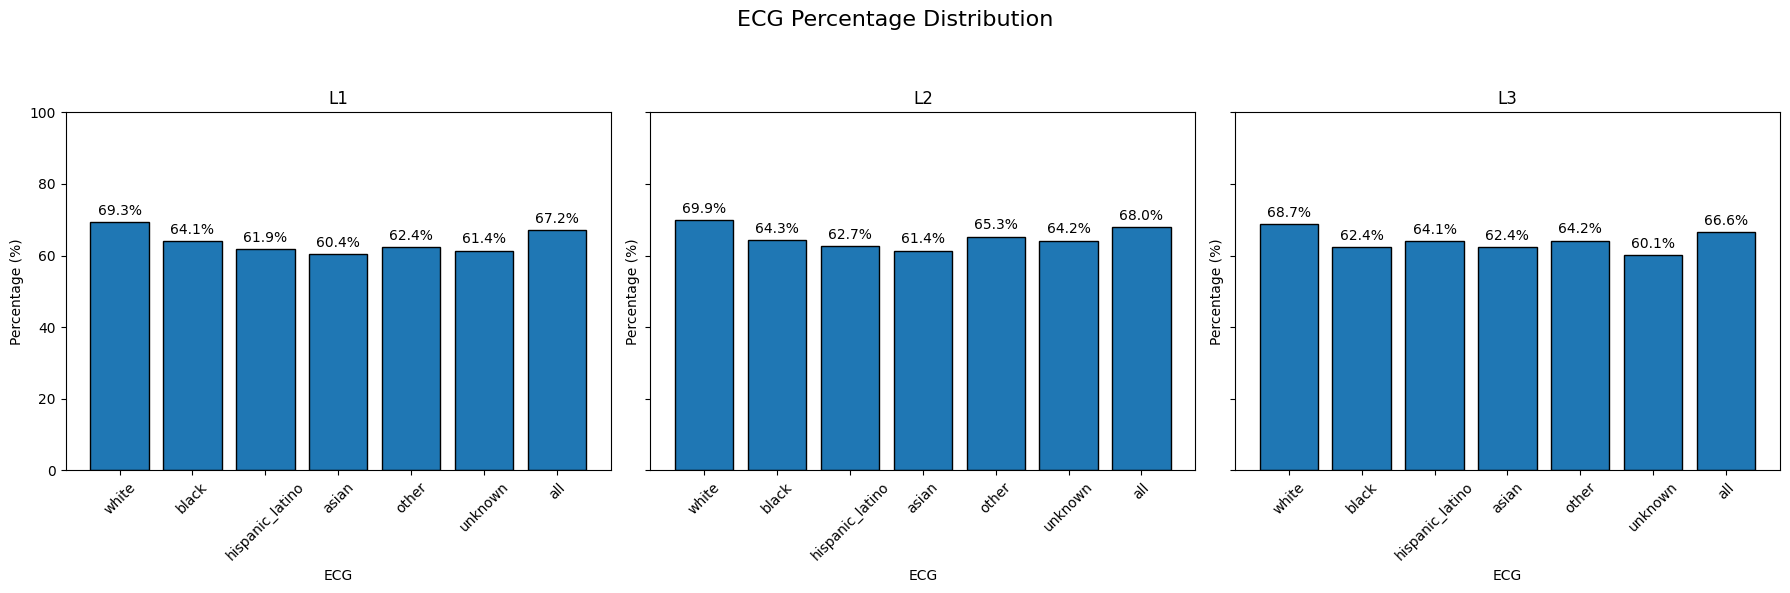

In [ ]:
do_they_have_dist('ecg_prop', 'ECG', 'ECG Percentage Distribution')

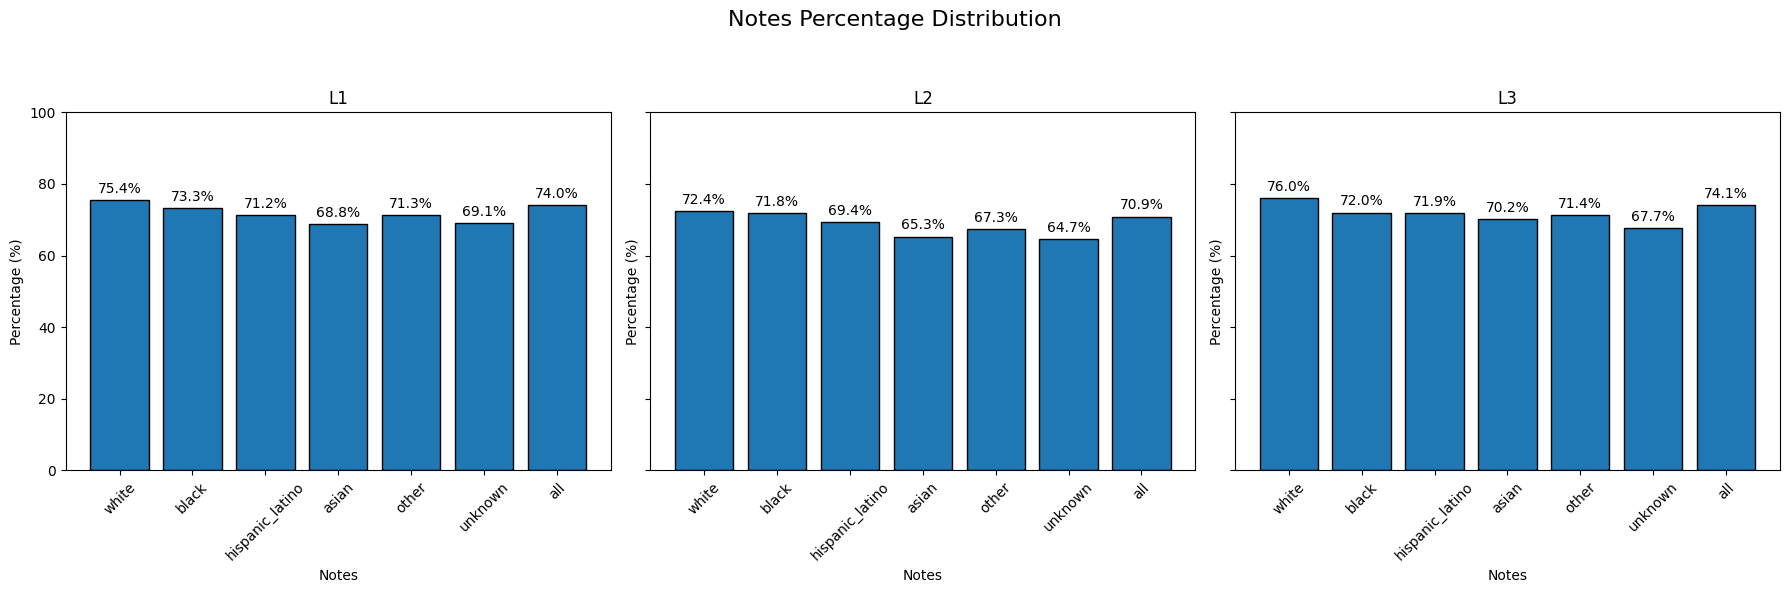

In [ ]:
do_they_have_dist('notes_prop', 'Notes', 'Notes Percentage Distribution')

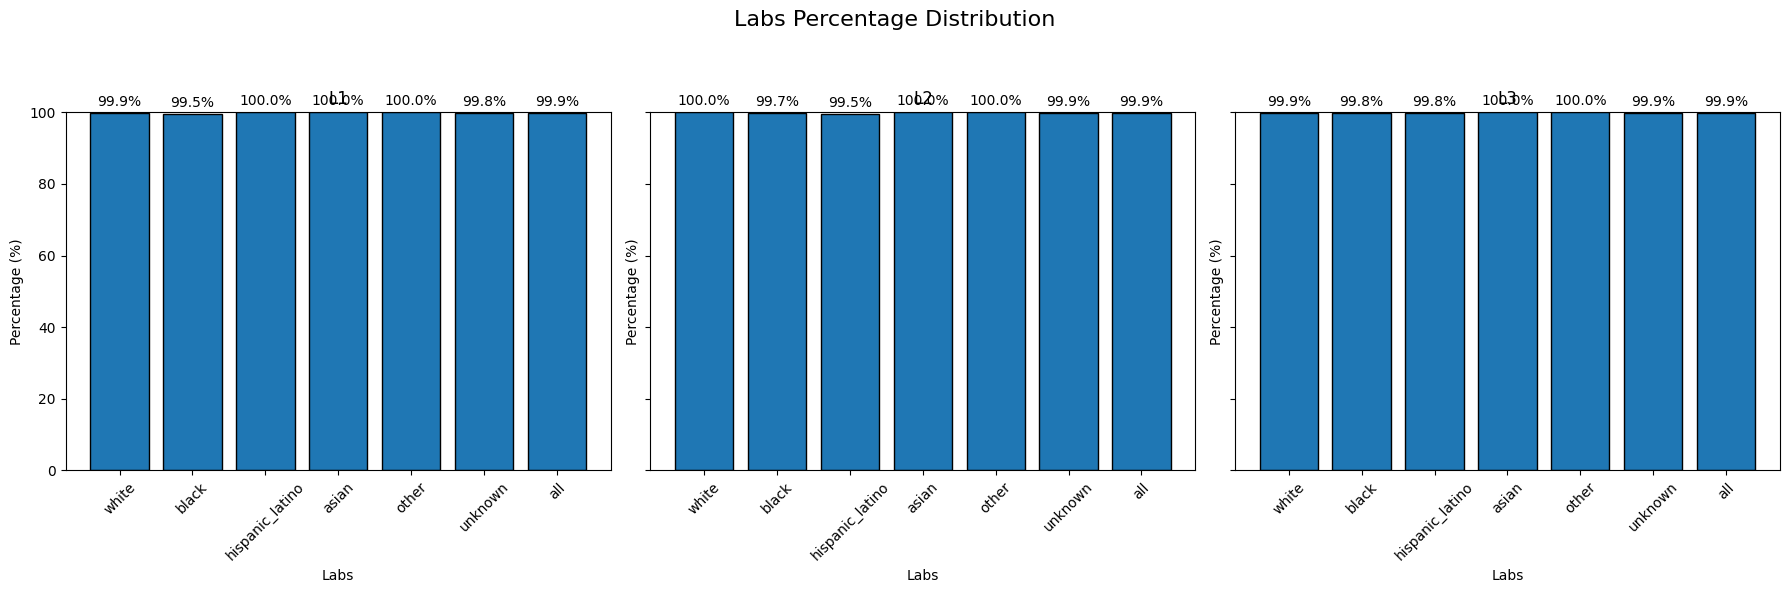

In [ ]:
do_they_have_dist('labs_prop', 'Labs', 'Labs Percentage Distribution')

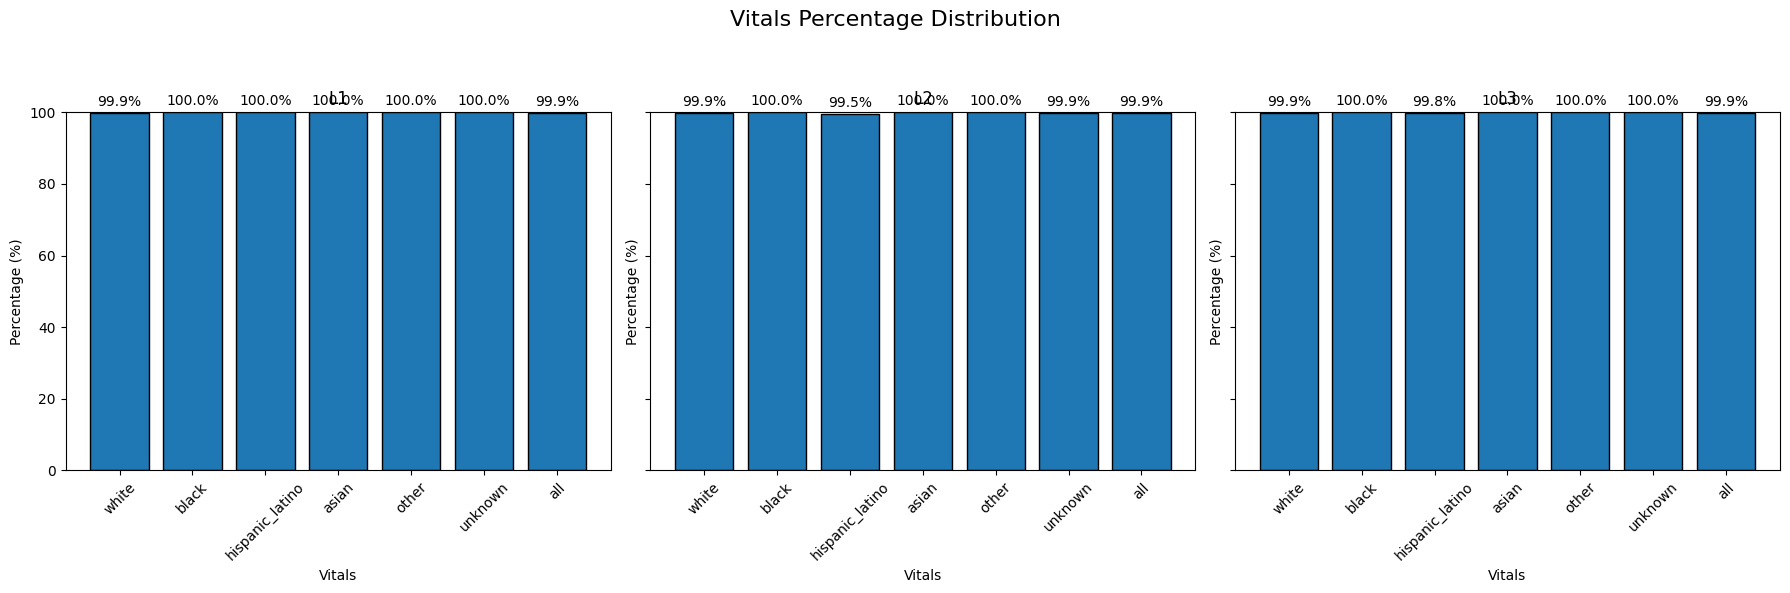

In [ ]:
do_they_have_dist('vitals_prop', 'Vitals', 'Vitals Percentage Distribution')

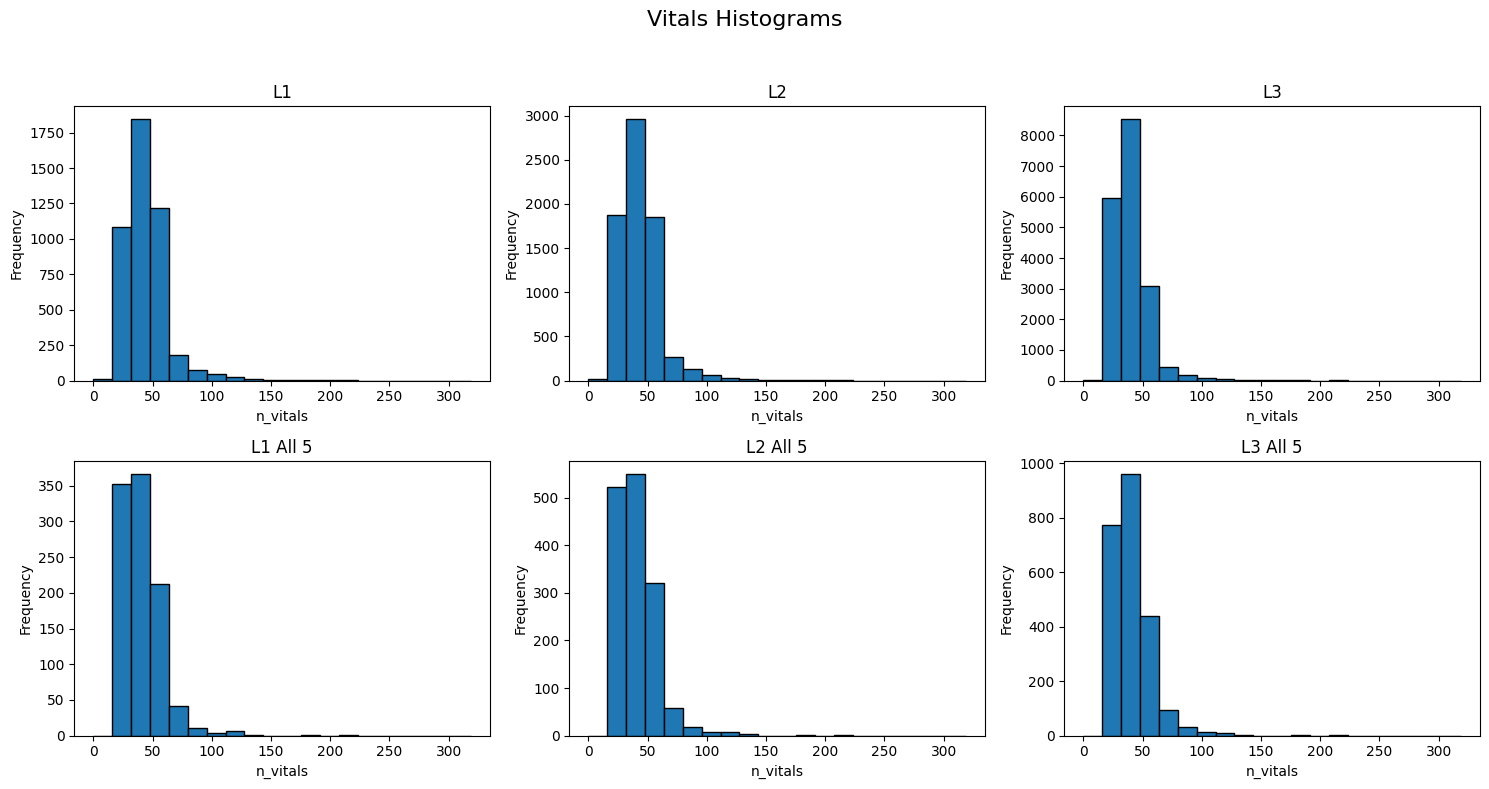

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

age_bins = np.linspace(min(df['n_vitals_base'].min() for df in df_list), max(df['n_vitals_base'].max() for df in df_list), 21)

for i, (df, title) in enumerate(zip(df_list, titles)):
    axes[i].hist(df['n_vitals_base'].dropna(), bins=age_bins, edgecolor='black')
    axes[i].set_title(title)
    axes[i].set_xlabel('n_vitals')
    axes[i].set_ylabel('Frequency')

fig.suptitle('Vitals Histograms', fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

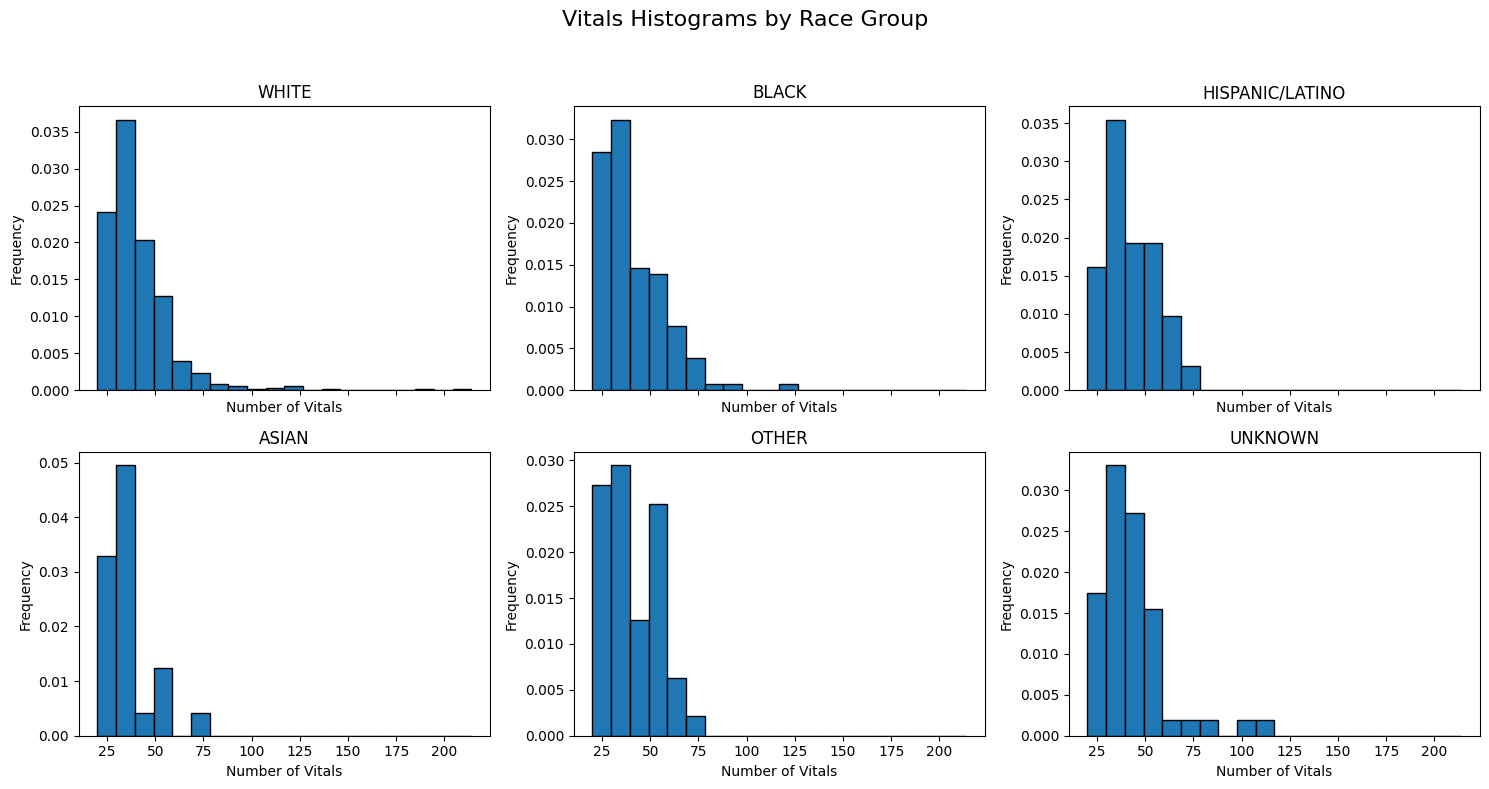

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True)
axes = axes.flatten()

# Use the same bins across all race groups
vitals1_bins = np.linspace(
    l1all_demo_df['n_vitals_base'].min(),
    l1all_demo_df['n_vitals_base'].max(),
    21
)

for i, race_group in enumerate(race_groupings_list[:-1]):
    race_df = l1all_demo_df[
        l1all_demo_df['race_group'] == race_group
    ]

    axes[i].hist(
        race_df['n_vitals_base'].dropna(),
        bins=vitals1_bins,
        edgecolor='black',
        density=True
    )
    axes[i].set_title(str(race_group))
    axes[i].set_xlabel('Number of Vitals')
    axes[i].set_ylabel('Frequency')

# Hide unused subplots if there are fewer than 6 race groups
for j in range(len(race_groupings_list), len(axes)):
    axes[j].set_visible(False)

fig.suptitle('Vitals Histograms by Race Group', fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

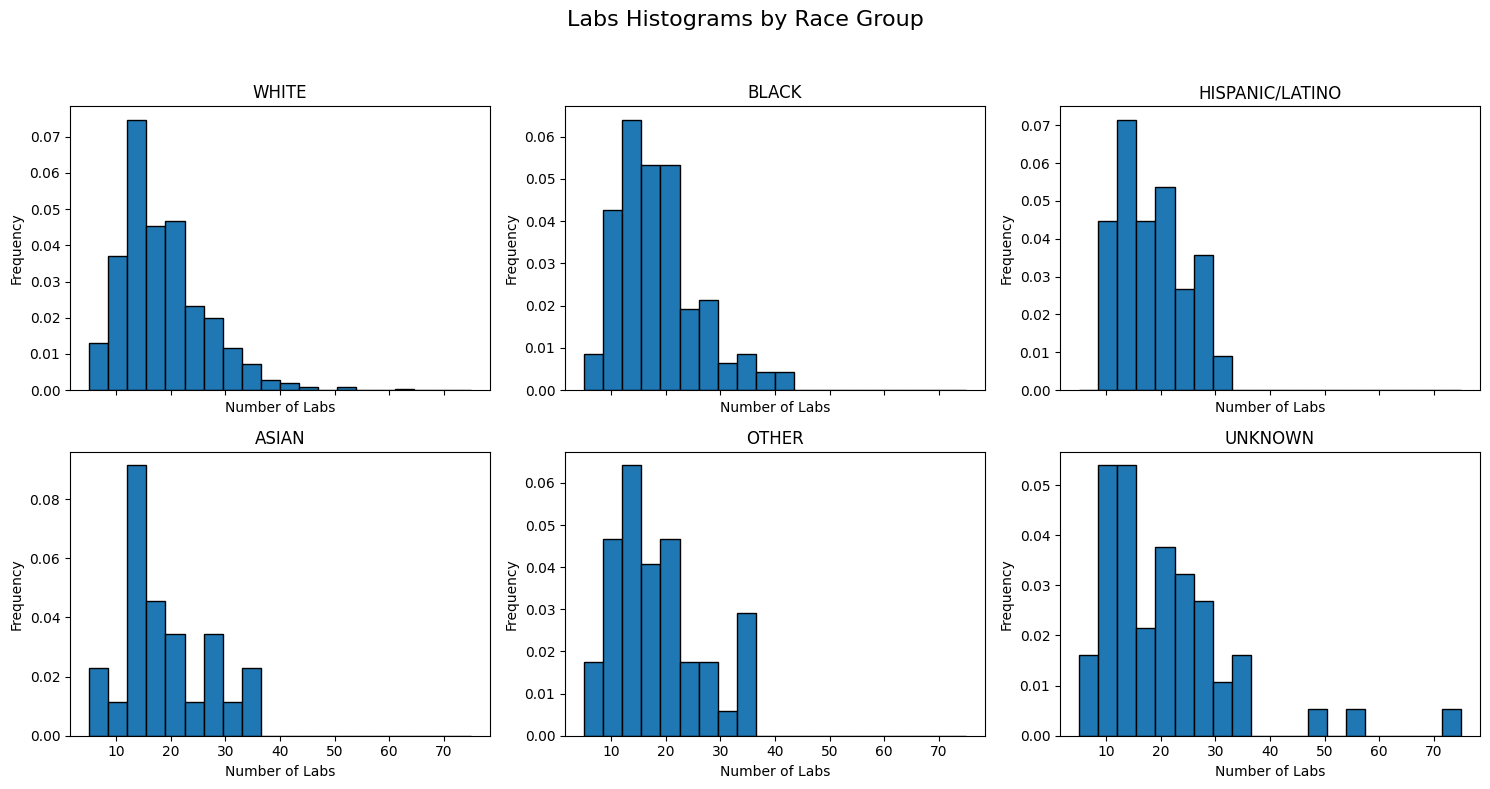

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True)
axes = axes.flatten()

# Use the same bins across all race groups
vitals1_bins = np.linspace(
    l1all_demo_df['n_labs_base'].min(),
    l1all_demo_df['n_labs_base'].max(),
    21
)

for i, race_group in enumerate(race_groupings_list[:-1]):
    race_df = l1all_demo_df[
        l1all_demo_df['race_group'] == race_group
    ]

    axes[i].hist(
        race_df['n_labs_base'].dropna(),
        bins=vitals1_bins,
        edgecolor='black',
        density=True
    )
    axes[i].set_title(str(race_group))
    axes[i].set_xlabel('Number of Labs')
    axes[i].set_ylabel('Frequency')

# Hide unused subplots if there are fewer than 6 race groups
for j in range(len(race_groupings_list), len(axes)):
    axes[j].set_visible(False)

fig.suptitle('Labs Histograms by Race Group', fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()